# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


**Dataset required:** `global_energy_mix.csv` (not included with the uploaded notebook). Place it at `../data/global_energy_mix.csv` relative to this notebook, or change `data_path` in the setup cell. Run all cells from top to bottom.

In [2]:

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from pathlib import Path
import numpy as np

# Dataset: Global Energy Mix by Country and Source

# Correct file location
data_path = Path(
    r"C:\Users\vrund\OneDrive\Desktop\Data Visualization\data-viz-class-material-w2026-main\data-viz-class-material-w2026-main\data\global_energy_mix.csv"
)

# Check whether the file exists
if not data_path.exists():
    raise FileNotFoundError(
        f"CSV file not found at: {data_path}\n"
        "Please check that global_energy_mix.csv exists in the data folder."
    )

# Load dataset
df = pd.read_csv(data_path)

# Check required columns
required_columns = {"Region", "Country", "Source", "TWh"}
missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise ValueError(
        f"The dataset is missing required columns: {sorted(missing_columns)}"
    )

# Ensure TWh is numeric
df["TWh"] = pd.to_numeric(df["TWh"], errors="coerce")

# Remove rows that cannot be plotted
df = df.dropna(
    subset=["Region", "Country", "Source", "TWh"]
).copy()

# Source type mapping — reuse from lecture
source_category = {
    "Coal": "Fossil",
    "Oil": "Fossil",
    "Natural Gas": "Fossil",
    "Nuclear": "Low-carbon",
    "Hydro": "Low-carbon",
    "Wind": "Renewable",
    "Solar": "Renewable",
    "Other Renewables": "Renewable"
}

df["Source_Type"] = df["Source"].map(source_category)

# Colour-blind-friendly palette (Okabe–Ito inspired)
SOURCE_COLOURS = {
    "Coal": "#0072B2",
    "Oil": "#E69F00",
    "Natural Gas": "#009E73"
}

LOW_CARBON_COLOURS = [
    "#0072B2",
    "#E69F00"
]

# Display results
print(f"Loaded: {len(df):,} rows")
print(f"Countries: {df['Country'].nunique()}")
print(f"Regions: {df['Region'].nunique()}")
print(f"Energy sources: {df['Source'].nunique()}")

print("\nDataset Preview:")
display(df.head(10))

print("\nAvailable Columns:")
print(df.columns.tolist())

print("\nEnergy Source Categories:")
print(df[["Source", "Source_Type"]].drop_duplicates().sort_values("Source"))


Loaded: 103 rows
Countries: 15
Regions: 7
Energy sources: 8

Dataset Preview:


,Country,Region,Source,Share_pct,TWh,Source_Type
0,United States,North America,Coal,10,1015.0,Fossil
1,United States,North America,Oil,35,3220.0,Fossil
2,United States,North America,Natural Gas,34,3083.0,Fossil
3,United States,North America,Nuclear,9,798.0,Low-carbon
4,United States,North America,Hydro,3,339.0,Low-carbon
5,United States,North America,Wind,4,413.0,Renewable
6,United States,North America,Solar,3,325.0,Renewable
7,United States,North America,Other Renewables,2,229.0,Renewable
8,China,Asia,Coal,58,6929.1,Fossil
9,China,Asia,Oil,18,1620.0,Fossil



Available Columns:
['Country', 'Region', 'Source', 'Share_pct', 'TWh', 'Source_Type']

Energy Source Categories:
             Source Source_Type
0              Coal      Fossil
4             Hydro  Low-carbon
2       Natural Gas      Fossil
3           Nuclear  Low-carbon
1               Oil      Fossil
7  Other Renewables   Renewable
6             Solar   Renewable
5              Wind   Renewable


## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

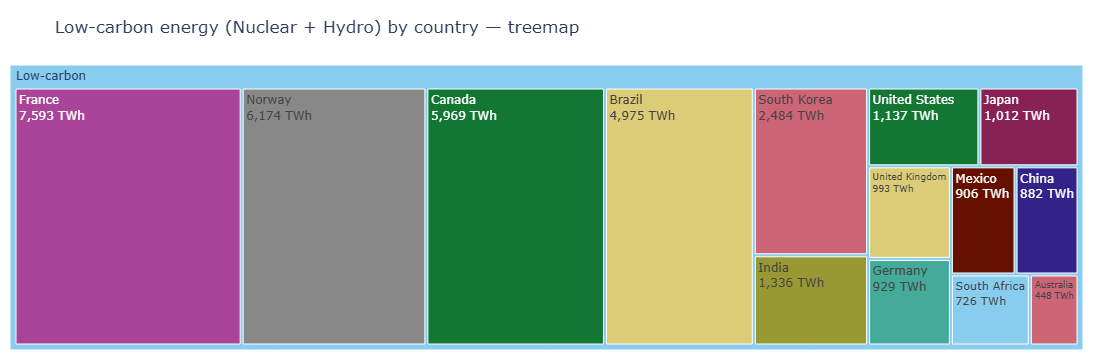

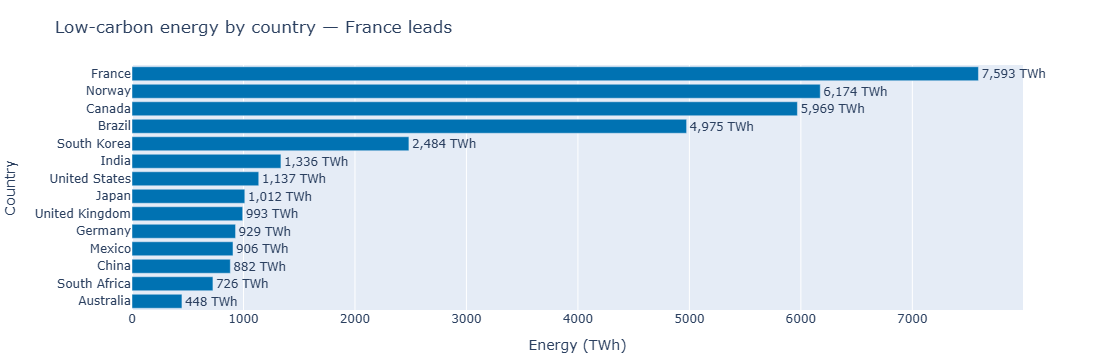

Insight: France has the highest combined Nuclear + Hydro output at 7,593.0 TWh.


In [3]:
# Task 2 — Low-carbon energy treemap and horizontal bar chart

# Keep Nuclear and Hydro (Source_Type == "Low-carbon") and aggregate by country.
df_low_carbon = df.loc[df["Source_Type"] == "Low-carbon"].copy()

if df_low_carbon.empty:
    raise ValueError("No low-carbon rows were found. Check the Source values in the CSV.")

low_carbon_country = (
    df_low_carbon.groupby("Country", as_index=False)["TWh"]
    .sum()
    .sort_values("TWh", ascending=False)
)
low_carbon_country["All"] = "Low-carbon"

# Treemap: single-level hierarchy under the dummy root 'Low-carbon'.
fig2a = px.treemap(
    low_carbon_country,
    path=["All", "Country"],
    values="TWh",
    color="Country",
    color_discrete_sequence=px.colors.qualitative.Safe
)
fig2a.update_traces(
    texttemplate="%{label}<br>%{value:,.0f} TWh",
    hovertemplate="<b>%{label}</b><br>%{value:,.2f} TWh<extra></extra>"
)
fig2a.update_layout(
    title="Low-carbon energy (Nuclear + Hydro) by country — treemap",
    margin=dict(t=65, l=10, r=10, b=10)
)
fig2a.show()

# Horizontal bar chart: sorted from highest to lowest.
leading_country = low_carbon_country.iloc[0]
fig2b = px.bar(
    low_carbon_country.sort_values("TWh", ascending=True),
    x="TWh",
    y="Country",
    orientation="h",
    text="TWh",
    color_discrete_sequence=["#0072B2"]
)
fig2b.update_traces(
    texttemplate="%{text:,.0f} TWh",
    textposition="outside",
    cliponaxis=False
)
fig2b.update_layout(
    title=f"Low-carbon energy by country — {leading_country['Country']} leads",
    xaxis_title="Energy (TWh)",
    yaxis_title="Country",
    margin=dict(t=65, l=10, r=70, b=10)
)
fig2b.show()

print(
    f"Insight: {leading_country['Country']} has the highest combined Nuclear + Hydro "
    f"output at {leading_country['TWh']:,.1f} TWh."
)

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

The horizontal bar chart tells the ranking story more clearly because all countries share the same numerical axis. It is easy to compare bar lengths and identify the highest and lowest values. The treemap is useful for showing the part-to-whole relationship and the relative size of each country's contribution, but comparing similarly sized rectangles is less precise.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

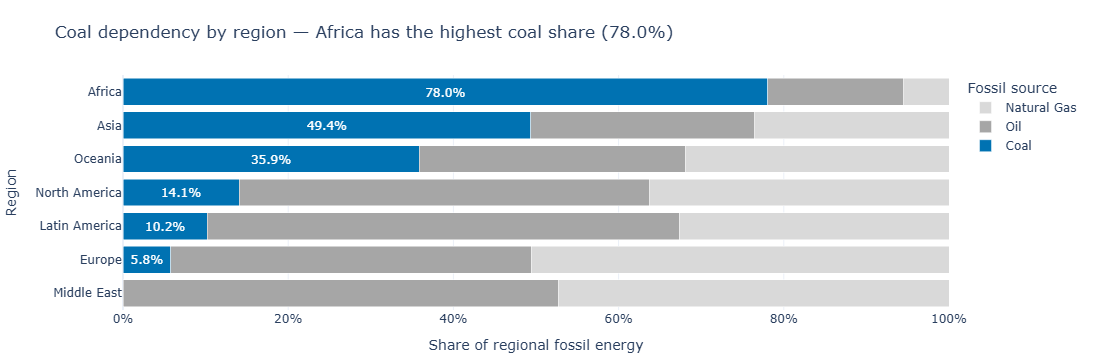

Insight: Africa is the most coal-dependent region: coal represents 78.0% of its fossil-energy total.


In [6]:

# Task 3 — 100% stacked bar: regional fossil-energy mix

# Step 1: Create fossil-energy dataset
df_fossil = df[
    df["Source_Type"] == "Fossil"
].copy()

# Step 2: Aggregate fossil TWh by Region and Source
regional_source = (
    df_fossil.groupby(["Region", "Source"], as_index=False)["TWh"]
    .sum()
)

# Step 3: Convert each source value into its share of that region's fossil-energy total
regional_source["Region_Total"] = (
    regional_source.groupby("Region")["TWh"].transform("sum")
)

regional_source["Share"] = (
    regional_source["TWh"] / regional_source["Region_Total"]
)

# Step 4: Ensure all three fossil categories are present
regions = df_fossil.groupby("Region")["TWh"].sum().index.tolist()

fossil_sources = ["Coal", "Oil", "Natural Gas"]

share_table = (
    regional_source.pivot(
        index="Region",
        columns="Source",
        values="Share"
    )
    .reindex(index=regions, columns=fossil_sources)
    .fillna(0)
)

# Step 5: Sort regions by coal share, highest at the top
coal_share = share_table["Coal"].sort_values(ascending=False)

ordered_regions = coal_share.index.tolist()

# Step 6: Create figure
fig3 = go.Figure()

segment_colours = {
    "Coal": SOURCE_COLOURS["Coal"],
    "Oil": "#A6A6A6",
    "Natural Gas": "#D9D9D9"
}

# Step 7: Add fossil energy sources
for source in fossil_sources:

    shares = share_table.loc[ordered_regions, source]

    # Percentage labels appear only on Coal
    text_labels = [
        f"{v:.1%}" if source == "Coal" and v > 0 else ""
        for v in shares
    ]

    fig3.add_trace(go.Bar(
        name=source,
        y=ordered_regions,
        x=shares,
        orientation="h",
        marker_color=segment_colours[source],
        text=text_labels,
        textposition="inside" if source == "Coal" else "none",
        insidetextanchor="middle",
        hovertemplate=f"{source}: %{{x:.1%}}<extra></extra>"
    ))

# Step 8: Update chart layout
fig3.update_layout(
    barmode="stack",

    title=(
        f"Coal dependency by region — {coal_share.index[0]} "
        f"has the highest coal share ({coal_share.iloc[0]:.1%})"
    ),

    xaxis=dict(
        title="Share of regional fossil energy",
        tickformat=".0%",
        range=[0, 1]
    ),

    yaxis=dict(
        title="Region",
        categoryorder="array",
        categoryarray=ordered_regions,
        autorange="reversed"
    ),

    legend_title="Fossil source",

    template="plotly_white",

    margin=dict(t=75, l=10, r=10, b=10)
)

# Step 9: Display chart
fig3.show()

# Step 10: Print insight
print(
    f"Insight: {coal_share.index[0]} is the most coal-dependent region: "
    f"coal represents {coal_share.iloc[0]:.1%} of its fossil-energy total."
)


### Task 3 — reflection



The treemap answers which individual countries and energy sources contribute the largest amounts of fossil energy. It shows the distribution of fossil energy across regions, countries, and energy sources.

The 100% stacked bar chart answers what percentage of fossil energy comes from coal, oil, and natural gas in each region. It helps identify which region depends most on coal and compare the energy mix between regions.